#UTS TEXT MINING
2702388322 - AMANDA SUGITO - LA06

LINK DRIVE : https://drive.google.com/drive/folders/1PDvo_wZatCAakRUMWpDQi9y2FhGl-68w?usp=sharing

##1. Mengumpulkan data review games dengan tema yang anda suka dengan cara scrapping sebanyak 2000 data dengan berbagai nilai rating. Anda juga memutuskan untuk mengumpulkan data review dalam bahasa Inggris.

In [ ]:
!pip install google-play-scraper

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 50.2/50.2 kB 2.0 MB/s eta 0:00:00


In [ ]:
from google_play_scraper import reviews, Sort
import pandas as pd

result, continuation_token = reviews(
    'me.pou.app',
    lang='en',
    country='us',
    sort=Sort.NEWEST,
    count=2000
)

df = pd.DataFrame(result)

df = df[['content', 'score']]

df.columns = ['review', 'rating']

df.to_csv('pou_reviews.csv', index=False)

df.head()

,review,rating
0,i like it but ill rate it a four,4
1,this is a baby game there are very good game i...,4
2,pou is my childhood game and I love this game ...,5
3,I know about everyone playing this game of Pet,5
4,childhood carrier 3000,5


In [ ]:
#cek jumlah data
df.shape

(2000, 2)

In [ ]:
#cek distribusi data
df['rating'].value_counts()

,count
rating,
5,1487
1,246
4,157
3,66
2,44


In [ ]:
#download data
from google.colab import files
files.download('pou_reviews.csv')

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

##2. Anda ingin mengenal data yang anda scrapping, maka anda melakukan exploratory terhadap data untuk melihat kata-kata yang dominan disetiap rating dan memeriksa apakah kata-kata yang tidak sesuai dengan standar bahasa punya frekuensi yang besar

In [ ]:
df.isnull().sum()

,0
review,1
rating,0


bersihin missing value

In [ ]:
df = df.dropna()

In [ ]:
df.isnull().sum()

,0
review,0
rating,0


bersihin text

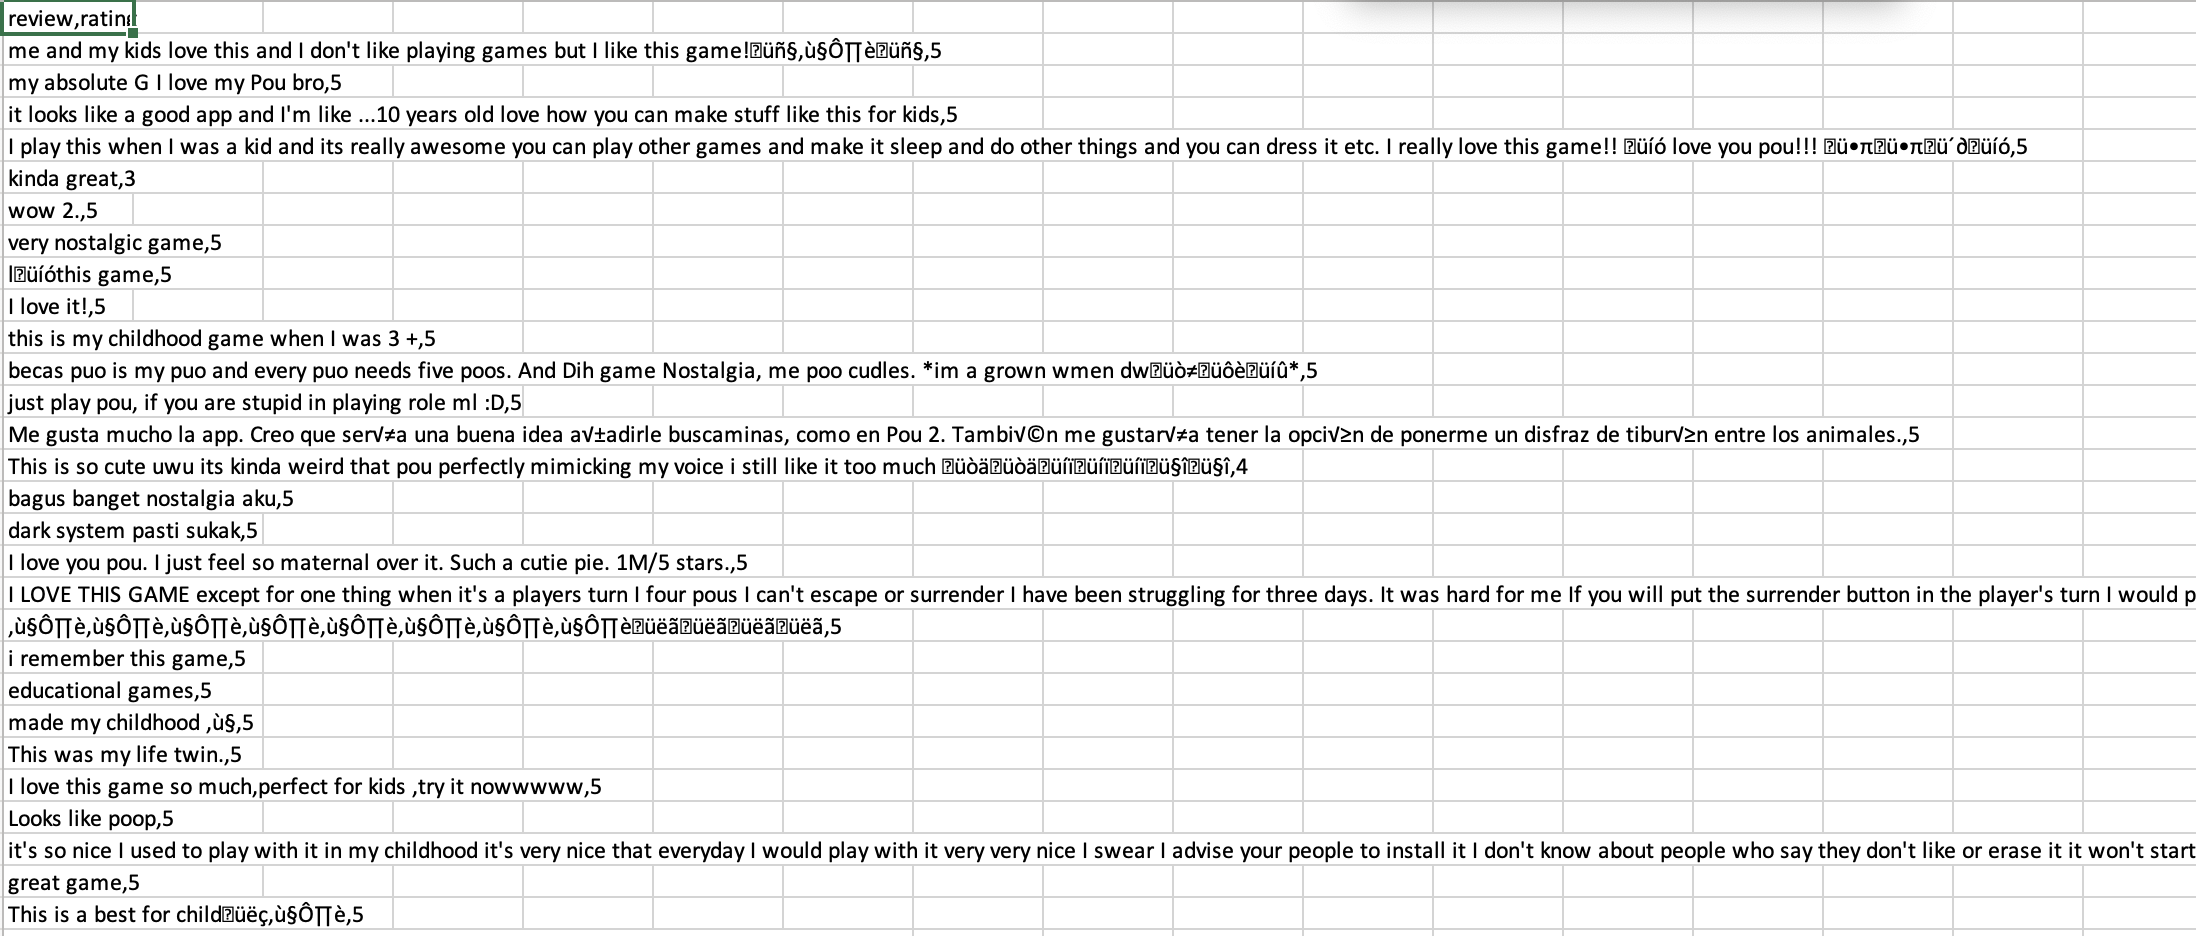

In [ ]:
import re

def clean_text(text):
    text = text.lower()
    text = re.sub(r'[^a-z\s]', '', text)
    return text

In [ ]:
df['rating'].value_counts().sort_index()

rating_groups = {}

for i in range(1, 6):
    rating_groups[i] = df[df['rating'] == i]['review']

cari kata yang dominan

In [ ]:
from collections import Counter

for i in range(1, 6):
    text = " ".join(rating_groups[i])
    words = text.split()

    counter = Counter(words)

    print(f"\nTop 10 words for rating {i}:")
    print(counter.most_common(10))


Top 10 words for rating 1:
[('I', 97), ('the', 97), ('to', 73), ('and', 68), ('it', 66), ('game', 63), ('is', 54), ('this', 51), ('i', 49), ('horrible', 46)]

Top 10 words for rating 2:
[('the', 41), ('and', 36), ('to', 31), ('I', 30), ('it', 27), ('is', 18), ('game', 17), ('a', 15), ('but', 12), ('of', 12)]

Top 10 words for rating 3:
[('I', 37), ('the', 37), ('is', 29), ('and', 25), ('but', 24), ('to', 20), ('game', 20), ('it', 20), ('this', 17), ("it's", 13)]

Top 10 words for rating 4:
[('game', 88), ('I', 81), ('a', 74), ('the', 72), ('it', 70), ('is', 64), ('to', 61), ('and', 59), ('but', 58), ('this', 43)]

Top 10 words for rating 5:
[('I', 632), ('game', 608), ('this', 466), ('and', 404), ('is', 385), ('it', 301), ('a', 298), ('the', 290), ('to', 261), ('love', 259)]


kata yang tidak sesuai standar

In [ ]:
import re

for i in range(1, 6):
    text = " ".join(rating_groups[i])
    words = text.split()

    # ambil kata yang mengandung simbol / bukan huruf
    weird_words = [w for w in words if re.search(r'[^a-zA-Z]', w)]

    counter = Counter(weird_words)

    print(f"\nWeird / Non-standard words rating {i}:")
    print(counter.most_common(10))


Weird / Non-standard words rating 1:
[("don't", 14), ("it's", 13), ("can't", 9), ('it,', 5), ('2', 5), ("didn't", 5), ('5', 4), ('1', 4), ('.', 4), ("that's", 4)]

Weird / Non-standard words rating 2:
[("it's", 6), ("I've", 5), ('it,', 4), ("It's", 3), ("can't", 2), ('app.', 2), ('app,', 2), ('screen.', 2), ("doesn't", 2), ('score.', 2)]

Weird / Non-standard words rating 3:
[("it's", 13), ("I'm", 8), ("It's", 4), ('3', 3), ('game.', 3), ("don't", 3), (',', 3), ('😅', 2), ("doesn't", 2), ('انا', 2)]

Weird / Non-standard words rating 4:
[("it's", 36), ('it.', 9), ('4', 9), ("It's", 8), ("can't", 7), ("don't", 7), ("I'm", 6), ('game!', 6), ('👍', 5), ('5', 5)]

Weird / Non-standard words rating 5:
[("it's", 106), ("I'm", 39), ('5', 36), ('game.', 35), ("It's", 34), ("I've", 24), ('game,', 22), ("don't", 20), ('it.', 19), ('game!', 19)]


word cloud

In [ ]:
!pip install wordcloud

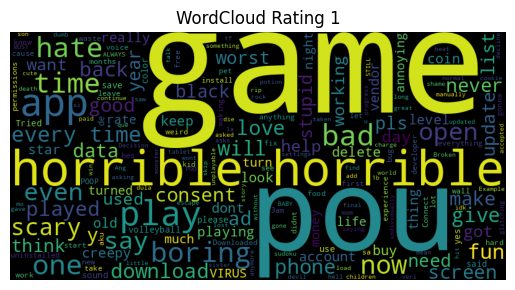

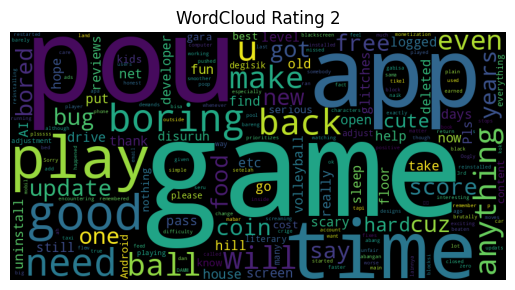

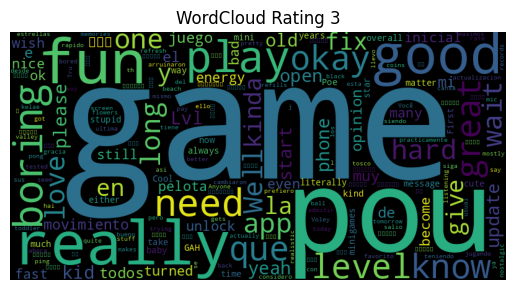

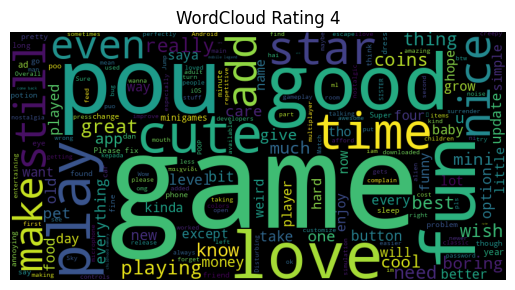

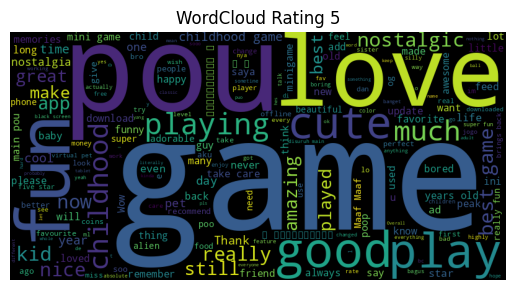

In [ ]:
from wordcloud import WordCloud
import matplotlib.pyplot as plt

for i in range(1, 6):
    text = " ".join(rating_groups[i])

    wc = WordCloud(width=800, height=400).generate(text)

    plt.figure()
    plt.imshow(wc)
    plt.axis('off')
    plt.title(f'WordCloud Rating {i}')
    plt.show()

##3. Melakukan preprocessing data hingga mendapatkan bentuk token paling efektif yang sesuai kaidah tata bahasa dan sebisa mungkin makna kata tersebut tidak berubah apalagi kelas katanya

Pada tahap preprocessing, dilakukan beberapa langkah untuk membersihkan dan menormalkan data teks. Proses yang dilakukan meliputi:

Mengubah seluruh teks menjadi huruf kecil (lowercase)

Menghapus karakter non-alfabet seperti angka dan simbol

Melakukan tokenisasi untuk memecah kalimat menjadi kata

Menghapus stopwords yang tidak memiliki makna signifikan

Melakukan lemmatization untuk mengubah kata ke bentuk dasar tanpa mengubah makna

Pendekatan lemmatization dipilih dibandingkan stemming karena dapat mempertahankan makna kata dan kelas kata, sesuai dengan kebutuhan analisis.

In [ ]:
!pip install nltk

In [ ]:
import nltk
import re
from nltk.corpus import stopwords
from nltk.tokenize import word_tokenize
from nltk.stem import WordNetLemmatizer

In [ ]:
nltk.download('punkt')
nltk.download('punkt_tab')
nltk.download('stopwords')
nltk.download('wordnet')
nltk.download('omw-1.4')

[nltk_data] Downloading package punkt to /root/nltk_data...
[nltk_data]   Unzipping tokenizers/punkt.zip.
[nltk_data] Downloading package punkt_tab to /root/nltk_data...
[nltk_data]   Unzipping tokenizers/punkt_tab.zip.
[nltk_data] Downloading package stopwords to /root/nltk_data...
[nltk_data]   Unzipping corpora/stopwords.zip.
[nltk_data] Downloading package wordnet to /root/nltk_data...
[nltk_data] Downloading package omw-1.4 to /root/nltk_data...


True

In [ ]:
stop_words = set(stopwords.words('english'))
stop_words.remove('not')
lemmatizer = WordNetLemmatizer()

In [ ]:
def preprocess_text(text):
    # lowercase
    text = text.lower()

    # expand contraction
    text = text.replace("don't", "do not")
    text = text.replace("can't", "can not")
    text = text.replace("i'm", "i am")
    text = text.replace("it's", "it is")

    # remove simbol & angka
    text = re.sub(r'[^a-z\s]', '', text)

    # tokenisasi
    tokens = word_tokenize(text)

    # remove stopwords
    tokens = [word for word in tokens if word not in stop_words]

    # lemmatization
    tokens = [lemmatizer.lemmatize(word) for word in tokens]

    return tokens

In [ ]:
df['tokens'] = df['review'].apply(preprocess_text)

In [ ]:
df[['review', 'tokens']].head()

,review,tokens
0,i like it but ill rate it a four,"[like, ill, rate, four]"
1,this is a baby game there are very good game i...,"[baby, game, good, game, iam, playing, game, i..."
2,pou is my childhood game and I love this game ...,"[pou, childhood, game, love, game, much]"
3,I know about everyone playing this game of Pet,"[know, everyone, playing, game, pet]"
4,childhood carrier 3000,"[childhood, carrier]"


In [ ]:
df['clean_text'] = df['tokens'].apply(lambda x: " ".join(x))

##4. Menerapkan 2 bentuk metode text representation yaitu, metode yang nilai vectornya merepresentasikan seberapa penting kata tersebut dalam suatu data sample, dan metode yang vectornya direpresentasikan oleh kata disekitarnya yang ditraining dengan model ANN dengan input kata dan target kata yang ada disekitarnya.

###4.1 Nilai vector merepresentasikan seberapa penting kata

Menggunakan Term Frequency – Inverse Document Frequency (TF-IDF) dengan cara mengubah teks menjadi vektor berdasarkan tingkat kepentingan kata dalam dokumen, di mana kata yang sering muncul dalam satu dokumen namun jarang di dokumen lain akan memiliki bobot lebih tinggi.

In [ ]:
from sklearn.feature_extraction.text import TfidfVectorizer

In [ ]:
X_text = df['clean_text']
y = df['rating']

In [ ]:
tfidf = TfidfVectorizer(max_features=5000)

X_tfidf = tfidf.fit_transform(X_text)

In [ ]:
X_tfidf.shape

(1999, 2898)

###4.2 Vectornya direpresentasikan oleh kata disekitarnya yang ditraining dengan model ANN dengan input kata dan target kata yang ada disekitarnya

Menggunakan Word2Vec yang merepresentasikan kata berdasarkan konteks di sekitarnya menggunakan model neural network. Dalam penelitian ini, representasi kalimat diperoleh dengan menghitung rata-rata vektor dari setiap kata dalam kalimat.

In [ ]:
!pip install gensim

In [ ]:
import gensim
from gensim.models import Word2Vec

In [ ]:
sentences = df['tokens']

In [ ]:
w2v_model = Word2Vec(
    sentences=sentences,
    vector_size=100,
    window=5,
    min_count=2,
    workers=4
)

cek contoh vector

In [ ]:
w2v_model.wv['game']

array([-0.17466386,  0.24757203,  0.09531152,  0.18246916, -0.00536715,
       -0.65559494,  0.3971384 ,  0.9420051 , -0.19336215, -0.22682452,
       -0.04555071, -0.51619965, -0.10224516,  0.13589078, -0.04248546,
       -0.17511296,  0.18173786, -0.36531478, -0.2295352 , -0.76420105,
        0.20195213,  0.2205327 ,  0.21536483, -0.12086723, -0.02641984,
        0.07788245, -0.41389343, -0.24045107, -0.38155803,  0.11943367,
        0.30136555,  0.17864335,  0.43985006, -0.48911837, -0.20180303,
        0.5612011 ,  0.04145683, -0.4119793 , -0.23174545, -0.6782632 ,
        0.03294617, -0.1988348 , -0.17084342, -0.04952883,  0.32532153,
       -0.02301902, -0.26155165,  0.07035025,  0.19075373,  0.2594581 ,
        0.15683466, -0.5753151 ,  0.03573594, -0.04822182, -0.15912873,
        0.24359967,  0.22155564, -0.07249057, -0.30423543,  0.34784794,
        0.19015138,  0.1479842 , -0.04268303, -0.16396692, -0.42831275,
        0.23325928,  0.28028613,  0.41023558, -0.61015385,  0.48

ubah jadi vector per review

In [ ]:
import numpy as np

def get_avg_vector(tokens, model, size):
    vectors = []

    for word in tokens:
        if word in model.wv:
            vectors.append(model.wv[word])

    if len(vectors) == 0:
        return np.zeros(size)

    return np.mean(vectors, axis=0)

In [ ]:
X_w2v = np.array([
    get_avg_vector(tokens, w2v_model, 100)
    for tokens in df['tokens']
])

In [ ]:
X_w2v.shape

(1999, 100)

##5. Melakukan pemodelan prediksi dengan menggunakan 2 metode Machine Learning dengan melakukan tuning hyperparameter (minimal 2 hyperparameter) untuk masing-masing algoritma machine learning

split data

In [ ]:
from sklearn.model_selection import train_test_split

# TF-IDF
X_train_tfidf, X_test_tfidf, y_train, y_test = train_test_split(
    X_tfidf, y, test_size=0.2, random_state=42
)

# Word2Vec
X_train_w2v, X_test_w2v, _, _ = train_test_split(
    X_w2v, y, test_size=0.2, random_state=42
)

###5.1 Logistic Regression

Membuat model logistic regression dan hyperparameter tuning dilakukan menggunakan GridSearchCV dengan beberapa parameter seperti nilai C dan max_iter pada Logistic Regression

In [ ]:
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import GridSearchCV

param_lr = {
    'C': [0.1, 1, 10],
    'max_iter': [100, 200]
}

###5.1.1 Logistic Regression untuk TF-IDF

In [ ]:
grid_lr_tfidf = GridSearchCV(
    LogisticRegression(),
    param_lr,
    cv=3,
    scoring='accuracy'
)

grid_lr_tfidf.fit(X_train_tfidf, y_train)

best_lr_tfidf = grid_lr_tfidf.best_estimator_

###5.1.2 Logistic Regression untuk Word2Vec

In [ ]:
grid_lr_w2v = GridSearchCV(
    LogisticRegression(),
    param_lr,
    cv=3,
    scoring='accuracy'
)

grid_lr_w2v.fit(X_train_w2v, y_train)

best_lr_w2v = grid_lr_w2v.best_estimator_

###5.2 Random Forest

Membuat model random forest dan hyperparameter tunning dilakukan menggunakan GridSearchCV dengan beberapa parameter, yaitu n_estimators dan max_depth

In [ ]:
from sklearn.ensemble import RandomForestClassifier

param_rf = {
    'n_estimators': [100, 200],
    'max_depth': [10, 20]
}

###5.2.1 Random Forest untuk TF-IDF

In [ ]:
grid_rf_tfidf = GridSearchCV(
    RandomForestClassifier(),
    param_rf,
    cv=3,
    scoring='accuracy'
)

grid_rf_tfidf.fit(X_train_tfidf, y_train)

best_rf_tfidf = grid_rf_tfidf.best_estimator_

###5.2.2 Random Forest untuk Word2Vec

In [ ]:
grid_rf_w2v = GridSearchCV(
    RandomForestClassifier(),
    param_rf,
    cv=3,
    scoring='accuracy'
)

grid_rf_w2v.fit(X_train_w2v, y_train)

best_rf_w2v = grid_rf_w2v.best_estimator_

##6. Menggunakan suatu metode deep learning, yaitu Long Short-Term Memory (LSTM) dengan metode text representation yang digunakan adalah pendekatan dengan vectornya direpresentasikan oleh kata disekitarnya yang ditraining dengan model ANN. Hyperparameter yang digunakan adalah jumlah epoch, batch size, dan jumlah unit.

Import library

In [ ]:
import numpy as np
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import LSTM, Dense, Embedding
from tensorflow.keras.preprocessing.sequence import pad_sequences
from tensorflow.keras.preprocessing.text import Tokenizer
from sklearn.preprocessing import LabelEncoder

Tokenizer

In [ ]:
tokenizer = Tokenizer(num_words=5000)
tokenizer.fit_on_texts(df['clean_text'])

X_seq = tokenizer.texts_to_sequences(df['clean_text'])

Padding

In [ ]:
X_pad = pad_sequences(X_seq, maxlen=100)

Encode label

In [ ]:
le = LabelEncoder()
y_encoded = le.fit_transform(y)

Split data

In [ ]:
from sklearn.model_selection import train_test_split

X_train_dl, X_test_dl, y_train_dl, y_test_dl = train_test_split(
    X_pad, y_encoded, test_size=0.2, random_state=42
)

Buat model LSTM

In [ ]:
lstm_model = Sequential()

lstm_model.add(Embedding(input_dim=5000, output_dim=100, input_length=100))
lstm_model.add(LSTM(64))
lstm_model.add(Dense(5, activation='softmax'))

lstm_model.compile(
    loss='sparse_categorical_crossentropy',
    optimizer='adam',
    metrics=['accuracy']
)

/usr/local/lib/python3.12/dist-packages/keras/src/layers/core/embedding.py:100: UserWarning: Argument `input_length` is deprecated. Just remove it.
  warnings.warn(


In [ ]:
history = lstm_model.fit(
    X_train_dl,
    y_train_dl,
    epochs=10,
    batch_size=32,
    validation_split=0.2
)

Epoch 1/10
40/40 ━━━━━━━━━━━━━━━━━━━━ 11s 176ms/step - accuracy: 0.7240 - loss: 0.9778 - val_accuracy: 0.7375 - val_loss: 0.8831
Epoch 2/10
40/40 ━━━━━━━━━━━━━━━━━━━━ 7s 107ms/step - accuracy: 0.7428 - loss: 0.8460 - val_accuracy: 0.7375 - val_loss: 0.8723
Epoch 3/10
40/40 ━━━━━━━━━━━━━━━━━━━━ 3s 75ms/step - accuracy: 0.7459 - loss: 0.7771 - val_accuracy: 0.7437 - val_loss: 0.8091
Epoch 4/10
40/40 ━━━━━━━━━━━━━━━━━━━━ 7s 132ms/step - accuracy: 0.7991 - loss: 0.6407 - val_accuracy: 0.7656 - val_loss: 0.7650
Epoch 5/10
40/40 ━━━━━━━━━━━━━━━━━━━━ 5s 129ms/step - accuracy: 0.8382 - loss: 0.5319 - val_accuracy: 0.7656 - val_loss: 0.7500
Epoch 6/10
40/40 ━━━━━━━━━━━━━━━━━━━━ 8s 76ms/step - accuracy: 0.8726 - loss: 0.4391 - val_accuracy: 0.7281 - val_loss: 0.8263
Epoch 7/10
40/40 ━━━━━━━━━━━━━━━━━━━━ 3s 67ms/step - accuracy: 0.8827 - loss: 0.3869 - val_accuracy: 0.7500 - val_loss: 0.8106
Epoch 8/10
40/40 ━━━━━━━━━━━━━━━━━━━━ 4s 103ms/step - accuracy: 0.8984 - loss: 0.3437 - val_accuracy: 0.75

##7. Evaluation

###7.1 Machine Learning Evaluation

In [ ]:
from sklearn.metrics import classification_report, accuracy_score

models = {
    "LR_TFIDF": best_lr_tfidf,
    "LR_W2V": best_lr_w2v,
    "RF_TFIDF": best_rf_tfidf,
    "RF_W2V": best_rf_w2v
}

for name, model in models.items():
    if "TFIDF" in name:
        X_test = X_test_tfidf
    else:
        X_test = X_test_w2v

    y_pred = model.predict(X_test)

    print(f"\n{name}")
    print("Accuracy:", accuracy_score(y_test, y_pred))
    print(classification_report(y_test, y_pred))


LR_TFIDF
Accuracy: 0.77
              precision    recall  f1-score   support

           1       0.56      0.36      0.44        50
           2       0.00      0.00      0.00         6
           3       0.00      0.00      0.00        11
           4       0.29      0.06      0.10        33
           5       0.81      0.96      0.88       300

    accuracy                           0.77       400
   macro avg       0.33      0.28      0.28       400
weighted avg       0.70      0.77      0.72       400


LR_W2V
Accuracy: 0.75
              precision    recall  f1-score   support

           1       0.00      0.00      0.00        50
           2       0.00      0.00      0.00         6
           3       0.00      0.00      0.00        11
           4       0.00      0.00      0.00        33
           5       0.75      1.00      0.86       300

    accuracy                           0.75       400
   macro avg       0.15      0.20      0.17       400
weighted avg       0.56      

/usr/local/lib/python3.12/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/usr/local/lib/python3.12/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/usr/local/lib/python3.12/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/usr/local/lib/python3.12/dist-packages/sklearn/m

Berdasarkan hasil evaluasi, model cenderung hanya mampu memprediksi kelas mayoritas yaitu rating 5 dengan baik, namun gagal dalam memprediksi kelas lainnya. Hal ini terlihat dari nilai recall dan f1-score yang sangat rendah pada rating 1 hingga 4.

Meskipun nilai accuracy cukup tinggi, hal ini tidak mencerminkan performa model yang sebenarnya karena adanya ketidakseimbangan data (data imbalance). Oleh karena itu, diperlukan penanganan terhadap data imbalance.

Berdasarkan hasil perbandingan, Logistic Regression menunjukkan performa yang lebih baik dibandingkan Random Forest. Hal ini terlihat dari nilai accuracy yang lebih tinggi serta kemampuan yang sedikit lebih baik dalam memprediksi kelas selain mayoritas.

Random Forest cenderung lebih bias terhadap kelas mayoritas dan gagal memprediksi sebagian besar kelas minoritas.

Oleh karena itu, Logistic Regression dipilih sebagai model machine learning yang lebih optimal pada tahap ini, terutama ketika menggunakan representasi TF-IDF.

Selain itu, representasi TF-IDF memberikan hasil yang lebih baik dibandingkan Word2Vec pada model machine learning, karena mampu menangkap pentingnya kata secara langsung dalam konteks klasifikasi.

###7.2 Deep Learning Evaluation

In [ ]:
import numpy as np

y_pred_dl = lstm_model.predict(X_test_dl)

# ambil kelas tertinggi
y_pred_dl = np.argmax(y_pred_dl, axis=1)

13/13 ━━━━━━━━━━━━━━━━━━━━ 1s 52ms/step


In [ ]:
from sklearn.metrics import classification_report, accuracy_score

print("Accuracy:", accuracy_score(y_test_dl, y_pred))
print(classification_report(y_test_dl, y_pred_dl))

Accuracy: 0.0
              precision    recall  f1-score   support

           0       0.26      0.30      0.28        50
           1       0.12      0.33      0.17         6
           2       0.00      0.00      0.00        11
           3       0.10      0.18      0.13        33
           4       0.83      0.66      0.74       300

    accuracy                           0.56       400
   macro avg       0.26      0.30      0.26       400
weighted avg       0.67      0.56      0.60       400



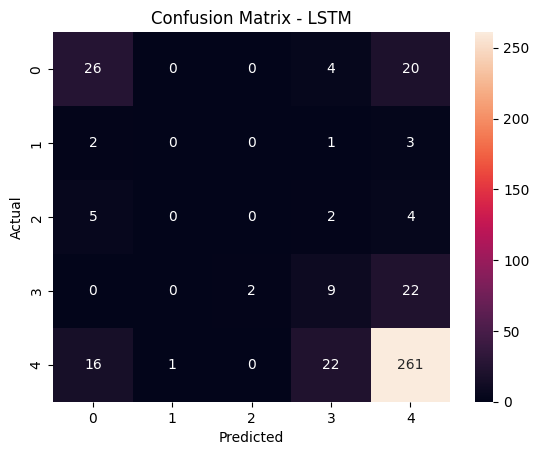

In [ ]:
from sklearn.metrics import confusion_matrix
import matplotlib.pyplot as plt
import seaborn as sns

cm = confusion_matrix(y_test_dl, y_pred_dl)

plt.figure()
sns.heatmap(cm, annot=True, fmt='d')
plt.xlabel('Predicted')
plt.ylabel('Actual')
plt.title('Confusion Matrix - LSTM')
plt.show()

In [ ]:
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score
import pandas as pd
import numpy as np

results = []

for name, model in models.items():
    if "TFIDF" in name:
        X_test = X_test_tfidf
        rep = "TF-IDF"
    else:
        X_test = X_test_w2v
        rep = "Word2Vec"

    y_pred = model.predict(X_test)

    results.append({
        "Text Representation": rep,
        "Model": name,
        "Accuracy": accuracy_score(y_test, y_pred),
        "Precision": precision_score(y_test, y_pred, average='macro', zero_division=0),
        "Recall": recall_score(y_test, y_pred, average='macro', zero_division=0),
        "F1-score": f1_score(y_test, y_pred, average='macro', zero_division=0)
    })

# predict DL
y_pred_dl = lstm_model.predict(X_test_dl)
y_pred_dl = np.argmax(y_pred_dl, axis=1)

results.append({
    "Text Representation": "Word2Vec",
    "Model": "LSTM",
    "Accuracy": accuracy_score(y_test_dl, y_pred_dl),
    "Precision": precision_score(y_test_dl, y_pred_dl, average='macro', zero_division=0),
    "Recall": recall_score(y_test_dl, y_pred_dl, average='macro', zero_division=0),
    "F1-score": f1_score(y_test_dl, y_pred_dl, average='macro', zero_division=0)
})

13/13 ━━━━━━━━━━━━━━━━━━━━ 1s 36ms/step


buat tabel

In [ ]:
df_results = pd.DataFrame(results)

df_results = df_results.sort_values(by="F1-score", ascending=False).reset_index(drop=True)

df_results

,Text Representation,Model,Accuracy,Precision,Recall,F1-score
0,Word2Vec,LSTM,0.7700,0.338514,0.313091,0.321775
1,TF-IDF,LR_TFIDF,0.7700,0.331441,0.276121,0.283415
2,Word2Vec,RF_W2V,0.7575,0.294898,0.218667,0.207342
3,TF-IDF,RF_TFIDF,0.7500,0.150000,0.200000,0.171429
4,Word2Vec,LR_W2V,0.7500,0.150000,0.200000,0.171429


##8. Melakukan treatment terhadap data imbalance dan melakukan training kembali dan melakukan evaluasi terhadap model dengan kondisi data baru. Anda membandingkan evaluasi performancenya dan mendapatkan kesimpulan model mana yang terbaik.

In [ ]:
df['rating'].value_counts()

,count
rating,
5,1486
1,246
4,157
3,66
2,44


Bisa dilihat kalau data sangat imbalance, jadi kita akan handle imbalanced data ini dengan dua cara :
1. Synthetic Minority Oversampling Technique (SMOTE) untuk machine learning
2. Class weight untuk deep learning

###8.1 SMOTE

install & import library

In [ ]:
!pip install imbalanced-learn

In [ ]:
from imblearn.over_sampling import SMOTE
import collections

applying SMOTE

In [ ]:
smote = SMOTE(random_state=42)

X_train_tfidf_smote, y_train_smote = smote.fit_resample(X_train_tfidf, y_train)

cek distribusi

In [ ]:
print("Before:", collections.Counter(y_train))
print("After :", collections.Counter(y_train_smote))

Before: Counter({5: 1186, 1: 196, 4: 124, 3: 55, 2: 38})
After : Counter({1: 1186, 5: 1186, 3: 1186, 2: 1186, 4: 1186})


SMOTE digunakan untuk menyeimbangkan jumlah data pada setiap kelas dengan cara menghasilkan data sintetis pada kelas minoritas. Setelah penerapan SMOTE, distribusi data menjadi lebih seimbang.

####8.1.1 Logistic Regression + SMOTE

In [ ]:
from imblearn.over_sampling import SMOTE

smote = SMOTE(random_state=42)

#####8.1.1.1 TF-IDF

In [ ]:
X_train_tfidf_smote, y_train_smote = smote.fit_resample(X_train_tfidf, y_train)

buat model

In [ ]:
from sklearn.model_selection import GridSearchCV
from sklearn.linear_model import LogisticRegression

param_lr = {
    'C': [0.1, 1, 10],
    'solver': ['liblinear', 'lbfgs']
}

grid_lr_tfidf_smote = GridSearchCV(
    LogisticRegression(max_iter=1000),
    param_lr,
    cv=3,
    scoring='accuracy'
)

grid_lr_tfidf_smote.fit(X_train_tfidf_smote, y_train_smote)

best_lr_tfidf_smote = grid_lr_tfidf_smote.best_estimator_

y_pred_tfidf_smote = best_lr_tfidf_smote.predict(X_test_tfidf)

#####8.1.1.2 Word2Vec

In [ ]:
X_train_w2v_smote, y_train_w2v_smote = smote.fit_resample(X_train_w2v, y_train)

buat model

In [ ]:
grid_lr_w2v_smote = GridSearchCV(
    LogisticRegression(max_iter=1000),
    param_lr,
    cv=3,
    scoring='accuracy'
)

grid_lr_w2v_smote.fit(X_train_w2v_smote, y_train_w2v_smote)

best_lr_w2v_smote = grid_lr_w2v_smote.best_estimator_

y_pred_w2v_smote = best_lr_w2v_smote.predict(X_test_w2v)

#####8.1.1.3 LR + SMOTE Evaluation

In [ ]:
from sklearn.metrics import classification_report

print("TF-IDF + SMOTE")
print(classification_report(y_test, y_pred_tfidf_smote))

print("Word2Vec + SMOTE")
print(classification_report(y_test, y_pred_w2v_smote))

TF-IDF + SMOTE
              precision    recall  f1-score   support

           1       0.43      0.56      0.49        50
           2       0.00      0.00      0.00         6
           3       0.00      0.00      0.00        11
           4       0.08      0.12      0.10        33
           5       0.87      0.65      0.74       300

    accuracy                           0.56       400
   macro avg       0.28      0.27      0.27       400
weighted avg       0.72      0.56      0.63       400

Word2Vec + SMOTE
              precision    recall  f1-score   support

           1       0.22      0.52      0.31        50
           2       0.05      0.33      0.09         6
           3       0.00      0.00      0.00        11
           4       0.06      0.15      0.09        33
           5       0.87      0.36      0.51       300

    accuracy                           0.35       400
   macro avg       0.24      0.27      0.20       400
weighted avg       0.68      0.35      0.43  

Setelah penerapan SMOTE, terjadi penurunan nilai accuracy, namun terjadi peningkatan yang signifikan pada nilai recall dan F1-score untuk kelas minoritas. Hal ini menunjukkan bahwa model mulai tidak bias terhadap kelas mayoritas dan mulai mampu mengenali kelas-kelas lain.

Pada representasi Word2Vec, model mengalami penurunan yang cukup signifikan, yang kemungkinan disebabkan oleh hilangnya informasi penting akibat proses averaging dan penambahan data sintetis.

Oleh karena itu, representasi TF-IDF dengan SMOTE memberikan hasil yang lebih optimal dalam menangani data imbalance.

Penurunan accuracy bukan menunjukkan performa yang buruk, melainkan menunjukkan bahwa model menjadi lebih seimbang dalam melakukan klasifikasi.

Meskipun SMOTE telah diterapkan, model masih mengalami kesulitan dalam memprediksi kelas dengan jumlah data yang sangat sedikit seperti rating 2 dan 3.

Hal ini disebabkan oleh keterbatasan jumlah data serta kemiripan pola bahasa antar kelas, sehingga model tidak dapat membedakan karakteristik masing-masing kelas dengan baik.

Selain itu, representasi TF-IDF yang hanya berbasis frekuensi kata juga tidak mampu menangkap konteks secara mendalam.

####8.1.2 Random Forest + SMOTE

#####8.1.2.1 TF-IDF

buat model

In [ ]:
from sklearn.ensemble import RandomForestClassifier

rf_tfidf_smote = RandomForestClassifier(
    n_estimators=200,
    max_depth=20,
    random_state=42
)

rf_tfidf_smote.fit(X_train_tfidf_smote, y_train_smote)

y_pred_rf_tfidf_smote = rf_tfidf_smote.predict(X_test_tfidf)

#####8.1.2.2 Word2Vec

buat model

In [ ]:
rf_w2v_smote = RandomForestClassifier(
    n_estimators=200,
    max_depth=20,
    random_state=42
)

rf_w2v_smote.fit(X_train_w2v_smote, y_train_w2v_smote)

y_pred_rf_w2v_smote = rf_w2v_smote.predict(X_test_w2v)

#####8.1.2.3 Random Forest + SMOTE Evaluation

In [ ]:
from sklearn.metrics import classification_report

print("RF TF-IDF + SMOTE")
print(classification_report(y_test, y_pred_rf_tfidf_smote))

print("RF Word2Vec + SMOTE")
print(classification_report(y_test, y_pred_rf_w2v_smote))

RF TF-IDF + SMOTE
              precision    recall  f1-score   support

           1       0.25      0.70      0.37        50
           2       0.00      0.00      0.00         6
           3       0.00      0.00      0.00        11
           4       0.00      0.00      0.00        33
           5       0.86      0.65      0.74       300

    accuracy                           0.57       400
   macro avg       0.22      0.27      0.22       400
weighted avg       0.68      0.57      0.60       400

RF Word2Vec + SMOTE
              precision    recall  f1-score   support

           1       0.33      0.28      0.30        50
           2       0.17      0.17      0.17         6
           3       0.00      0.00      0.00        11
           4       0.08      0.06      0.07        33
           5       0.81      0.77      0.79       300

    accuracy                           0.62       400
   macro avg       0.28      0.26      0.27       400
weighted avg       0.66      0.62      

/usr/local/lib/python3.12/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/usr/local/lib/python3.12/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/usr/local/lib/python3.12/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))


Model Random Forest menunjukkan performa yang kurang stabil dalam menangani data imbalance.

Pada representasi TF-IDF, model mampu mengenali kelas ekstrem seperti rating 1 dan 5 dengan baik, namun gagal dalam mengklasifikasikan kelas menengah seperti rating 2, 3, dan 4. Hal ini disebabkan oleh karakteristik Random Forest yang kurang mampu menangkap pola yang ambigu dan overlap antar kelas.

Pada representasi Word2Vec, model menunjukkan sedikit peningkatan dalam mengenali kelas minoritas, namun secara keseluruhan performanya tetap lebih rendah dibandingkan TF-IDF.

Oleh karena itu, Random Forest kurang optimal untuk kasus klasifikasi dengan data yang memiliki tingkat ambiguitas tinggi seperti pada review teks.

###8.2 Class Weighting

Pada model deep learning, penanganan data imbalance dilakukan menggunakan teknik class weighting.

Metode ini memberikan bobot lebih besar pada kelas minoritas sehingga model lebih memperhatikan kesalahan pada kelas tersebut selama proses training.

hitung class weighting

In [ ]:
from sklearn.utils.class_weight import compute_class_weight
import numpy as np

class_weights = compute_class_weight(
    class_weight='balanced',
    classes=np.unique(y_train_dl),
    y=y_train_dl
)

class_weights = dict(enumerate(class_weights))
print(class_weights)

{0: np.float64(1.6316326530612244), 1: np.float64(8.41578947368421), 2: np.float64(5.8145454545454545), 3: np.float64(2.579032258064516), 4: np.float64(0.26964586846543004)}


buat model

In [ ]:
history = lstm_model.fit(
    X_train_dl,
    y_train_dl,
    epochs=10,
    batch_size=32,
    validation_split=0.2,
    class_weight=class_weights
)

Epoch 1/10
40/40 ━━━━━━━━━━━━━━━━━━━━ 6s 75ms/step - accuracy: 0.4504 - loss: 1.5998 - val_accuracy: 0.7094 - val_loss: 1.5255
Epoch 2/10
40/40 ━━━━━━━━━━━━━━━━━━━━ 3s 72ms/step - accuracy: 0.7756 - loss: 1.5540 - val_accuracy: 0.6438 - val_loss: 1.4560
Epoch 3/10
40/40 ━━━━━━━━━━━━━━━━━━━━ 4s 105ms/step - accuracy: 0.6771 - loss: 1.3968 - val_accuracy: 0.4875 - val_loss: 1.3358
Epoch 4/10
40/40 ━━━━━━━━━━━━━━━━━━━━ 3s 69ms/step - accuracy: 0.6904 - loss: 1.0843 - val_accuracy: 0.4844 - val_loss: 1.2307
Epoch 5/10
40/40 ━━━━━━━━━━━━━━━━━━━━ 3s 67ms/step - accuracy: 0.7740 - loss: 0.8844 - val_accuracy: 0.6187 - val_loss: 1.0482
Epoch 6/10
40/40 ━━━━━━━━━━━━━━━━━━━━ 3s 71ms/step - accuracy: 0.7975 - loss: 0.6548 - val_accuracy: 0.5875 - val_loss: 1.1272
Epoch 7/10
40/40 ━━━━━━━━━━━━━━━━━━━━ 4s 107ms/step - accuracy: 0.8116 - loss: 0.5066 - val_accuracy: 0.5594 - val_loss: 1.1321
Epoch 8/10
40/40 ━━━━━━━━━━━━━━━━━━━━ 3s 70ms/step - accuracy: 0.8405 - loss: 0.4386 - val_accuracy: 0.5813 -

evaluation

In [ ]:
import numpy as np
from sklearn.metrics import classification_report

y_pred_lstm_cw = lstm_model.predict(X_test_dl)
y_pred_lstm_cw = np.argmax(y_pred_lstm_cw, axis=1)

print(classification_report(y_test_dl, y_pred_lstm_cw))

13/13 ━━━━━━━━━━━━━━━━━━━━ 0s 31ms/step
              precision    recall  f1-score   support

           0       0.41      0.46      0.43        50
           1       0.11      0.33      0.17         6
           2       0.00      0.00      0.00        11
           3       0.11      0.15      0.12        33
           4       0.85      0.76      0.80       300

    accuracy                           0.65       400
   macro avg       0.30      0.34      0.31       400
weighted avg       0.70      0.65      0.67       400



In [ ]:
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score
import pandas as pd

def get_metrics(y_true, y_pred):
    return (
        accuracy_score(y_true, y_pred),
        precision_score(y_true, y_pred, average='macro', zero_division=0),
        recall_score(y_true, y_pred, average='macro', zero_division=0),
        f1_score(y_true, y_pred, average='macro', zero_division=0)
    )

results = []

#model  ML imbalanced

for name, model in models.items():
    if "TFIDF" in name:
        X_test = X_test_tfidf
        rep = "TF-IDF"
    else:
        X_test = X_test_w2v
        rep = "Word2Vec"

    y_pred = model.predict(X_test)

    acc, prec, rec, f1 = get_metrics(y_test, y_pred)

    results.append([name, rep, "Normal", acc, prec, rec, f1])

#model ML + SMOTE

results.append(["LR", "TF-IDF", "SMOTE", *get_metrics(y_test, y_pred_tfidf_smote)])
results.append(["LR", "Word2Vec", "SMOTE", *get_metrics(y_test, y_pred_w2v_smote)])

results.append(["RF", "TF-IDF", "SMOTE", *get_metrics(y_test, y_pred_rf_tfidf_smote)])
results.append(["RF", "Word2Vec", "SMOTE", *get_metrics(y_test, y_pred_rf_w2v_smote)])

#model LSTM imbalanced

# LSTM NORMAL
results.append(["LSTM", "Word2Vec", "Normal", *get_metrics(y_test_dl, y_pred_dl)])

# LSTM CLASS WEIGHT
results.append(["LSTM", "Word2Vec", "Class Weight", *get_metrics(y_test_dl, y_pred_lstm_cw)])

#print dataframe

df_final = pd.DataFrame(results, columns=[
    "Model", "Representation", "Method", "Accuracy", "Precision", "Recall", "F1-score"
])

df_final

,Model,Representation,Method,Accuracy,Precision,Recall,F1-score
0,LR_TFIDF,TF-IDF,Normal,0.7700,0.331441,0.276121,0.283415
1,LR_W2V,Word2Vec,Normal,0.7500,0.150000,0.200000,0.171429
2,RF_TFIDF,TF-IDF,Normal,0.7500,0.150000,0.200000,0.171429
3,RF_W2V,Word2Vec,Normal,0.7575,0.294898,0.218667,0.207342
4,LR,TF-IDF,SMOTE,0.5650,0.277595,0.265576,0.265803
5,LR,Word2Vec,SMOTE,0.3550,0.239765,0.273636,0.199642
6,RF,TF-IDF,SMOTE,0.5725,0.222406,0.269333,0.221997
7,RF,Word2Vec,SMOTE,0.6225,0.275507,0.256121,0.265200
8,LSTM,Word2Vec,Normal,0.5550,0.263378,0.295697,0.264912
9,LSTM,Word2Vec,Class Weight,0.6475,0.295271,0.341636,0.305828


In [ ]:
df_final["Model"] = df_final["Model"].replace({
    "LR_TFIDF": "LR",
    "LR_W2V": "LR",
    "RF_TFIDF": "RF",
    "RF_W2V": "RF"
})

model_order = ["LR", "RF", "LSTM"]
rep_order = ["TF-IDF", "Word2Vec"]
method_order = ["Normal", "SMOTE", "Class Weight"]

df_final["Model"] = pd.Categorical(df_final["Model"], categories=model_order, ordered=True)
df_final["Representation"] = pd.Categorical(df_final["Representation"], categories=rep_order, ordered=True)
df_final["Method"] = pd.Categorical(df_final["Method"], categories=method_order, ordered=True)

df_final = df_final.sort_values(by=["Model", "Representation", "Method"]).reset_index(drop=True)

In [ ]:
df_final.style.highlight_max(
    subset=["Accuracy", "Precision", "Recall", "F1-score"],
    color='lightgreen'
)

,Model,Representation,Method,Accuracy,Precision,Recall,F1-score
0,LR,TF-IDF,Normal,0.770000,0.331441,0.276121,0.283415
1,LR,TF-IDF,SMOTE,0.565000,0.277595,0.265576,0.265803
2,LR,Word2Vec,Normal,0.750000,0.150000,0.200000,0.171429
3,LR,Word2Vec,SMOTE,0.355000,0.239765,0.273636,0.199642
4,RF,TF-IDF,Normal,0.750000,0.150000,0.200000,0.171429
5,RF,TF-IDF,SMOTE,0.572500,0.222406,0.269333,0.221997
6,RF,Word2Vec,Normal,0.757500,0.294898,0.218667,0.207342
7,RF,Word2Vec,SMOTE,0.622500,0.275507,0.256121,0.265200
8,LSTM,Word2Vec,Normal,0.555000,0.263378,0.295697,0.264912
9,LSTM,Word2Vec,Class Weight,0.647500,0.295271,0.341636,0.305828


Berdasarkan hasil evaluasi, model dengan accuracy tertinggi diperoleh oleh Logistic Regression dengan representasi TF-IDF tanpa penanganan imbalance. Namun, model tersebut menunjukkan performa yang kurang baik dalam mengklasifikasikan kelas minoritas.

Penerapan SMOTE mampu meningkatkan keseimbangan model, meskipun menyebabkan penurunan accuracy.

Representasi TF-IDF secara umum memberikan hasil yang lebih baik dibandingkan Word2Vec. Selain itu, Logistic Regression menunjukkan performa yang lebih stabil dibandingkan Random Forest.

Model LSTM dengan class weighting menghasilkan performa terbaik berdasarkan nilai F1-score, sehingga lebih efektif dalam menangani data yang tidak seimbang.